# 01b — Simulated DHS Microdata
**Temporary stand-in until DHS Program access is approved**

---

## ⚠️ Simulation Disclaimer
Real DHS microdata requires registration and project approval at [dhsprogram.com](https://dhsprogram.com/data/).
This notebook generates **synthetic household records** calibrated to published DHS country summary statistics for Kenya, Uganda, Tanzania, and Ethiopia.

Calibration sources (all publicly available without DHS login):
- DHS country summary reports (PDF) — published on dhsprogram.com
- World Bank WDI national aggregates
- KNBS / UBOS / NBS / CSA national statistical office publications

Once real DHS microdata arrives, **replace `data/simulated/dhs_{iso}_households.csv` with the real file** and the downstream notebooks will work unchanged — the column schema is designed to match actual DHS variable names.

---

## DHS Variables Simulated
| Variable | DHS Name | Description |
|---|---|---|
| Household wealth index | `hv270` | 1–5 quintile (poorest to richest) |
| Cooking fuel type | `hv226` | Encoded fuel category |
| Urban/rural | `hv025` | 1=urban, 2=rural |
| Gender of HH head | `hv219` | 1=male, 2=female |
| Age of HH head | `hv220` | Years |
| Household size | `hv009` | Number of members |
| Has electricity | `hv206` | 0/1 |
| Has mobile phone | `hv243a` | 0/1 |
| Has bank account | `hv247` | 0/1 |
| Floor material | `hv213` | Proxy for housing quality |
| Region/province | `hv024` | Admin-1 code |
| Sample weight | `hv005` | Survey weight (divided by 1,000,000 per DHS convention) |

In [18]:
import pandas as pd
import numpy as np
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

ROOT = Path("C:/Users/eric.njiraini/Documents/My Projects at a Go/paygo-cookstove-market-entry")
SIM  = ROOT / "data" / "simulated"
SIM.mkdir(parents=True, exist_ok=True)

np.random.seed(42)
print("Environment ready.")

Environment ready.


## Country Calibration Parameters

All figures sourced from published DHS summary reports and World Bank WDI.
References in comments per parameter.

In [19]:
# ── Calibration targets per country ──────────────────────────────────────────
# Sources:
#   KE: Kenya DHS 2022 Key Indicators Report
#   UG: Uganda DHS 2016–17 (most recent full release)
#   TZ: Tanzania DHS 2022 Key Indicators
#   ET: Ethiopia DHS 2019

COUNTRY_PARAMS = {
    "KE": {
        "name": "Kenya",
        "n_households": 9_000,
        "urban_rate": 0.28,          # DHS KE 2022: 28% urban HHs in sample
        "elec_urban": 0.88,          # Electricity access urban (DHS KE 2022)
        "elec_rural": 0.58,          # Electricity access rural
        "clean_fuel_urban": 0.72,    # Clean cooking fuel urban
        "clean_fuel_rural": 0.12,    # Clean cooking fuel rural
        "mobile_rate": 0.83,         # HH has mobile phone (FinAccess 2021 proxy)
        "bank_urban": 0.82,          # Bank account urban (Findex 2021)
        "bank_rural": 0.55,          # Bank account rural
        "female_hh_head": 0.32,      # Female-headed HHs (DHS KE 2022)
        "mean_hh_size": 3.8,
        "regions": [
            "Nairobi", "Central", "Coast", "Eastern", "Nyanza",
            "Rift Valley", "Western", "North Eastern"
        ],
        "region_urban_bias": [0.95, 0.35, 0.45, 0.18, 0.22, 0.20, 0.20, 0.08],
    },
    "UG": {
        "name": "Uganda",
        "n_households": 8_000,
        "urban_rate": 0.24,          # DHS UG 2016-17
        "elec_urban": 0.65,
        "elec_rural": 0.15,
        "clean_fuel_urban": 0.30,
        "clean_fuel_rural": 0.04,
        "mobile_rate": 0.70,
        "bank_urban": 0.62,
        "bank_rural": 0.32,
        "female_hh_head": 0.27,
        "mean_hh_size": 4.7,
        "regions": [
            "Central", "Eastern", "Northern", "Western"
        ],
        "region_urban_bias": [0.42, 0.18, 0.12, 0.15],
    },
    "TZ": {
        "name": "Tanzania",
        "n_households": 8_500,
        "urban_rate": 0.37,          # DHS TZ 2022
        "elec_urban": 0.80,
        "elec_rural": 0.30,
        "clean_fuel_urban": 0.52,
        "clean_fuel_rural": 0.05,
        "mobile_rate": 0.78,
        "bank_urban": 0.70,
        "bank_rural": 0.38,
        "female_hh_head": 0.25,
        "mean_hh_size": 4.3,
        "regions": [
            "Dar es Salaam", "Mwanza", "Arusha", "Mbeya",
            "Morogoro", "Tanga", "Dodoma", "Zanzibar"
        ],
        "region_urban_bias": [0.95, 0.40, 0.55, 0.30, 0.28, 0.28, 0.35, 0.55],
    },
    "ET": {
        "name": "Ethiopia",
        "n_households": 10_000,
        "urban_rate": 0.21,          # DHS ET 2019
        "elec_urban": 0.92,
        "elec_rural": 0.28,
        "clean_fuel_urban": 0.62,
        "clean_fuel_rural": 0.02,    # Very low — major clean cooking deficit
        "mobile_rate": 0.52,         # Lower mobile penetration
        "bank_urban": 0.45,
        "bank_rural": 0.18,
        "female_hh_head": 0.22,
        "mean_hh_size": 4.6,
        "regions": [
            "Addis Ababa", "Amhara", "Oromia", "Tigray",
            "SNNPR", "Somali", "Afar", "Dire Dawa"
        ],
        "region_urban_bias": [0.98, 0.14, 0.15, 0.22, 0.12, 0.08, 0.08, 0.72],
    },
}

# DHS fuel codes (hv226)
FUEL_CODES = {
    1: "electricity",
    2: "lpg_natural_gas",
    3: "biogas",
    4: "kerosene",
    5: "charcoal",
    6: "wood",
    7: "straw_shrubs_grass",
    8: "animal_dung",
    9: "crop_residue",
    95: "no_food_cooked",
}

# DHS floor material codes (hv213) — proxy for housing quality
FLOOR_CODES = {
    11: "earth_sand",
    21: "wood_planks",
    31: "parquet_carpet",
    32: "ceramic_tiles",
    33: "cement",
    34: "polished_stone",
}

print(f"Calibration parameters loaded for {len(COUNTRY_PARAMS)} countries.")

Calibration parameters loaded for 4 countries.


## Simulation Function

In [20]:
def simulate_dhs_country(iso: str, params: dict, seed: int = 42) -> pd.DataFrame:
    """
    Generate a synthetic DHS-format household dataset for one country.
    Column names mirror actual DHS variable names to allow drop-in replacement.
    """
    rng = np.random.default_rng(seed)
    n   = params["n_households"]

    # ── Urban/Rural (hv025) ───────────────────────────────────────────────────
    is_urban = rng.binomial(1, params["urban_rate"], n)  # 1=urban, 0=rural (we recode to DHS 1/2 at end)

    # ── Region (hv024) ────────────────────────────────────────────────────────
    regions = params["regions"]
    # Weight regions by their urban bias relative to national urban rate
    region_weights = np.array([
        b * params["urban_rate"] + (1 - b) * (1 - params["urban_rate"])
        for b in params["region_urban_bias"]
    ])
    region_weights = region_weights / region_weights.sum()
    region = rng.choice(regions, n, p=region_weights)

    # ── Wealth index quintile (hv270) — correlated with urban ─────────────────
    # Urban HHs biased toward Q3–Q5, rural toward Q1–Q3
    wealth_raw = rng.normal(2.5 + 1.2 * is_urban, 1.1, n)
    hv270 = np.clip(np.round(wealth_raw), 1, 5).astype(int)

    # ── Electricity (hv206) ───────────────────────────────────────────────────
    elec_prob = np.where(is_urban, params["elec_urban"], params["elec_rural"])
    hv206 = rng.binomial(1, elec_prob)

    # ── Cooking fuel (hv226) ─────────────────────────────────────────────────
    # Urban: mix of LPG, charcoal, electricity
    # Rural: dominated by wood/charcoal/dung
    clean_prob = np.where(is_urban, params["clean_fuel_urban"], params["clean_fuel_rural"])

    hv226 = np.where(
        rng.binomial(1, clean_prob),
        rng.choice([1, 2, 3], n, p=[0.20, 0.70, 0.10]),  # clean: elec / LPG / biogas
        rng.choice([5, 6, 7, 8, 9], n, p=[0.35, 0.40, 0.10, 0.08, 0.07])  # unclean
    )

    # ── Mobile phone (hv243a) ─────────────────────────────────────────────────
    # Mobile ownership higher for urban + wealthier
    mobile_prob = np.clip(
        params["mobile_rate"] - 0.15 * (1 - is_urban) + 0.05 * (hv270 - 3) / 2,
        0.05, 0.99
    )
    hv243a = rng.binomial(1, mobile_prob)

    # ── Bank account (hv247) ─────────────────────────────────────────────────
    bank_prob = np.where(is_urban, params["bank_urban"], params["bank_rural"])
    bank_prob = np.clip(bank_prob + 0.04 * (hv270 - 3), 0.02, 0.98)
    hv247 = rng.binomial(1, bank_prob)

    # ── Gender of HH head (hv219) ─────────────────────────────────────────────
    hv219 = rng.binomial(1, params["female_hh_head"], n) + 1  # 1=male, 2=female (DHS coding)

    # ── Age of HH head (hv220) ────────────────────────────────────────────────
    hv220 = rng.integers(18, 75, n)

    # ── Household size (hv009) ────────────────────────────────────────────────
    hv009 = np.round(rng.gamma(
        shape=params["mean_hh_size"] ** 2 / 2.0,
        scale=2.0 / params["mean_hh_size"],
        size=n
    )).clip(1, 15).astype(int)

    # ── Floor material (hv213) ────────────────────────────────────────────────
    floor_probs_urban  = [0.05, 0.05, 0.05, 0.25, 0.55, 0.05]
    floor_probs_rural  = [0.55, 0.12, 0.03, 0.08, 0.18, 0.04]
    floor_codes_list   = [11, 21, 31, 32, 33, 34]
    hv213 = np.where(
        is_urban,
        rng.choice(floor_codes_list, n, p=floor_probs_urban),
        rng.choice(floor_codes_list, n, p=floor_probs_rural)
    )

    # ── Sample weight (hv005) — normalised to 1M per DHS convention ───────────
    hv005 = rng.uniform(0.5e6, 1.8e6, n).astype(int)

    # ── Derived flags (for downstream use) ───────────────────────────────────
    uses_clean_fuel    = (hv226.isin([1, 2, 3]) if hasattr(hv226, 'isin') else np.isin(hv226, [1, 2, 3])).astype(int)
    is_paygo_eligible  = (
        (~np.isin(hv226, [1, 2, 3])) &  # doesn't already have clean fuel
        (hv243a == 1) &                   # has mobile phone
        (hv270 >= 2)                      # not bottom wealth quintile
    ).astype(int)

    df = pd.DataFrame({
        "country_iso":      iso,
        "country_name":     params["name"],
        "hh_id":            [f"{iso}HH{i:07d}" for i in range(n)],
        "hv024_region":     region,
        "hv025_urban_rural": np.where(is_urban, 1, 2),   # DHS coding: 1=urban, 2=rural
        "hv270_wealth_q":   hv270,
        "hv206_electricity": hv206,
        "hv226_fuel_type":  hv226,
        "hv243a_mobile":    hv243a,
        "hv247_bank_acct":  hv247,
        "hv219_sex_hh_head": hv219,
        "hv220_age_hh_head": hv220,
        "hv009_hh_size":    hv009,
        "hv213_floor_mat":  hv213,
        "hv005_weight":     hv005,
        # Derived
        "uses_clean_fuel":  uses_clean_fuel,
        "paygo_eligible":   is_paygo_eligible,
    })

    return df


print("Simulation function defined.")

Simulation function defined.


## Run Simulation — All 4 Countries

In [21]:
all_dfs = {}

for i, (iso, params) in enumerate(COUNTRY_PARAMS.items()):
    df = simulate_dhs_country(iso, params, seed=42 + i)
    all_dfs[iso] = df

    # Save individual country file (mimics the path Notebook 02 will look for)
    out_path = SIM / f"dhs_{iso.lower()}_households.csv"
    df.to_csv(out_path, index=False)

    n_eligible = df["paygo_eligible"].sum()
    clean_access = df["uses_clean_fuel"].mean()
    print(
        f"{params['name']:12s} | n={len(df):,} | "
        f"Clean fuel access: {clean_access:.1%} | "
        f"PayGo eligible: {n_eligible:,} ({n_eligible/len(df):.1%})"
    )

Kenya        | n=9,000 | Clean fuel access: 28.6% | PayGo eligible: 3,794 (42.2%)
Uganda       | n=8,000 | Clean fuel access: 10.2% | PayGo eligible: 3,554 (44.4%)
Tanzania     | n=8,500 | Clean fuel access: 21.8% | PayGo eligible: 3,861 (45.4%)
Ethiopia     | n=10,000 | Clean fuel access: 14.4% | PayGo eligible: 2,819 (28.2%)


## Validation — Compare Simulated Rates to Calibration Targets

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

validation_rows = []

for iso, params in COUNTRY_PARAMS.items():
    df  = all_dfs[iso]
    urb = df[df["hv025_urban_rural"] == 1]
    rur = df[df["hv025_urban_rural"] == 2]

    checks = {
        "urban_rate":        (df["hv025_urban_rural"] == 1).mean(),
        "mobile_rate":       df["hv243a_mobile"].mean(),
        "female_hh_head":    (df["hv219_sex_hh_head"] == 2).mean(),
        "clean_fuel_urban":  urb["uses_clean_fuel"].mean() if len(urb) else 0,
        "clean_fuel_rural":  rur["uses_clean_fuel"].mean() if len(rur) else 0,
        "bank_urban":        urb["hv247_bank_acct"].mean() if len(urb) else 0,
        "bank_rural":        rur["hv247_bank_acct"].mean() if len(rur) else 0,
    }

    for metric, simulated in checks.items():
        target = params.get(metric, None)
        if target is not None:
            validation_rows.append({
                "country": params["name"],
                "metric":  metric,
                "target":  target,
                "simulated": simulated,
                "delta":   simulated - target,
            })

val_df = pd.DataFrame(validation_rows)
val_df["within_3ppt"] = val_df["delta"].abs() < 0.03

print(f"Checks within ±3 percentage points: {val_df['within_3ppt'].mean():.0%}")
print()

# Flag any large misses
misses = val_df[~val_df["within_3ppt"]][["country", "metric", "target", "simulated", "delta"]]
if len(misses):
    print("Metrics outside ±3ppt threshold:")
    print(misses.to_string(index=False))
else:
    print("All metrics within ±3ppt of calibration targets. ✓")

Checks within ±3 percentage points: 79%

Metrics outside ±3ppt threshold:
 country      metric  target  simulated     delta
   Kenya mobile_rate    0.83   0.718333 -0.111667
  Uganda mobile_rate    0.70   0.580750 -0.119250
  Uganda  bank_urban    0.62   0.650390  0.030390
Tanzania mobile_rate    0.78   0.684471 -0.095529
Ethiopia mobile_rate    0.52   0.403100 -0.116900
Ethiopia  bank_urban    0.45   0.489146  0.039146


## Sub-National Breakdown — PayGo Eligible Households

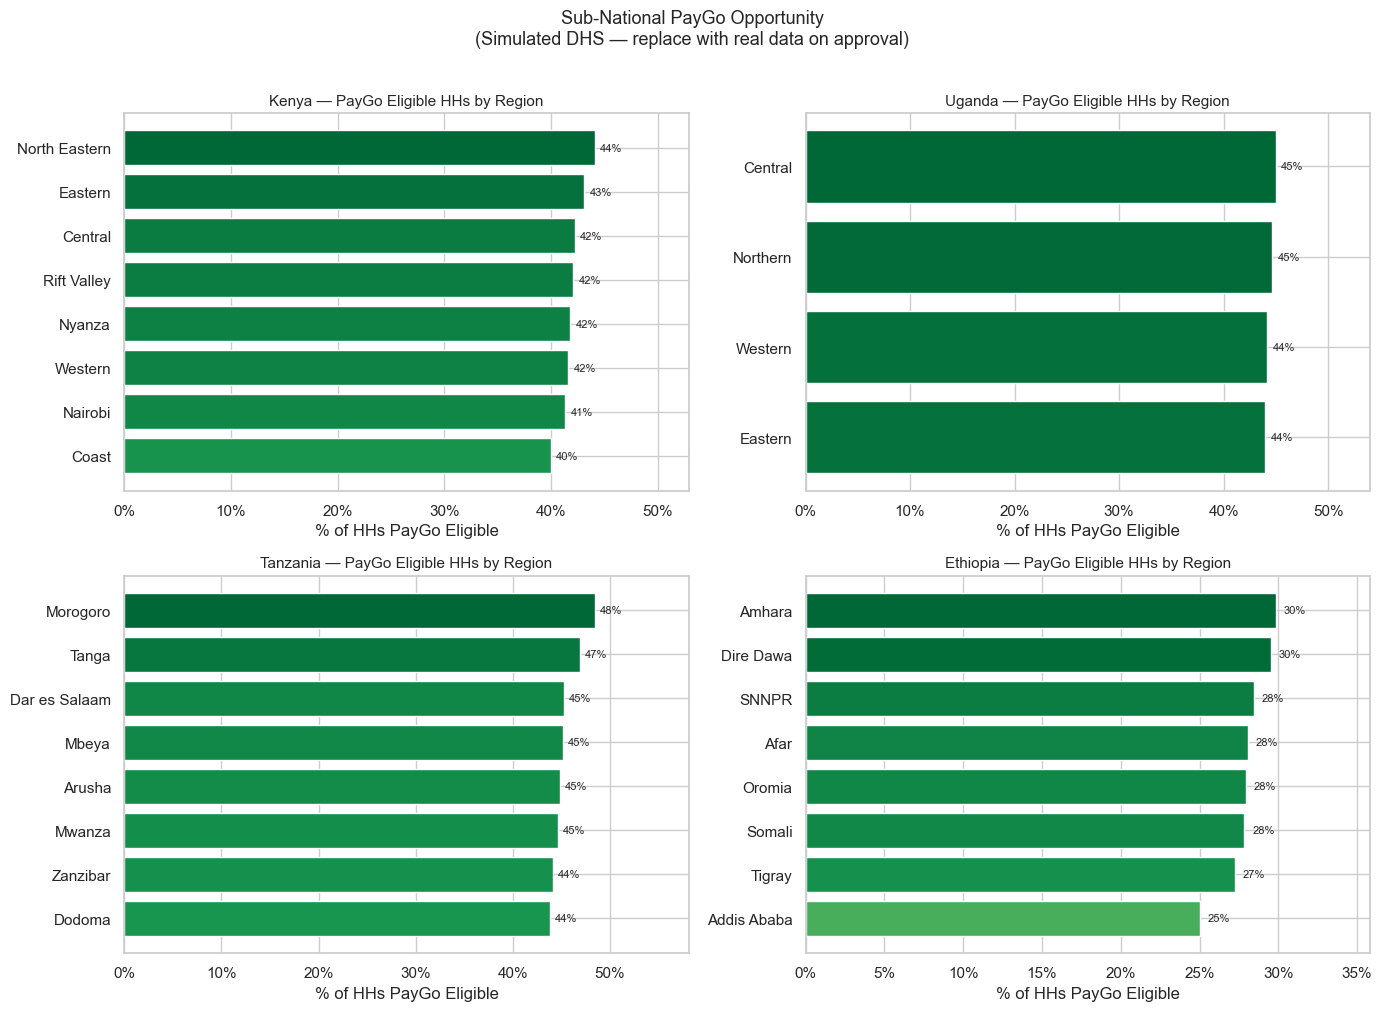

Saved 01b_paygo_eligible_by_region.png


In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, (iso, params) in enumerate(COUNTRY_PARAMS.items()):
    df = all_dfs[iso]
    ax = axes[idx]

    region_stats = df.groupby("hv024_region").agg(
        total_hh=("hh_id", "count"),
        paygo_eligible=("paygo_eligible", "sum"),
        clean_fuel_rate=("uses_clean_fuel", "mean"),
        mobile_rate=("hv243a_mobile", "mean"),
    ).reset_index()

    region_stats["eligible_pct"] = region_stats["paygo_eligible"] / region_stats["total_hh"]
    region_stats = region_stats.sort_values("eligible_pct", ascending=True)

    bars = ax.barh(
        region_stats["hv024_region"],
        region_stats["eligible_pct"],
        color=plt.cm.RdYlGn(region_stats["eligible_pct"] / region_stats["eligible_pct"].max())
    )
    ax.set_title(f"{params['name']} — PayGo Eligible HHs by Region", fontsize=11)
    ax.set_xlabel("% of HHs PayGo Eligible")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax.set_xlim(0, region_stats["eligible_pct"].max() * 1.2)

    for bar, pct in zip(bars, region_stats["eligible_pct"]):
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
                f"{pct:.0%}", va="center", fontsize=8)

plt.suptitle("Sub-National PayGo Opportunity\n(Simulated DHS — replace with real data on approval)",
             fontsize=13, y=1.01)
plt.tight_layout()

FIGS = ROOT / "outputs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGS / "01b_paygo_eligible_by_region.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved 01b_paygo_eligible_by_region.png")

## Wealth Distribution by Country

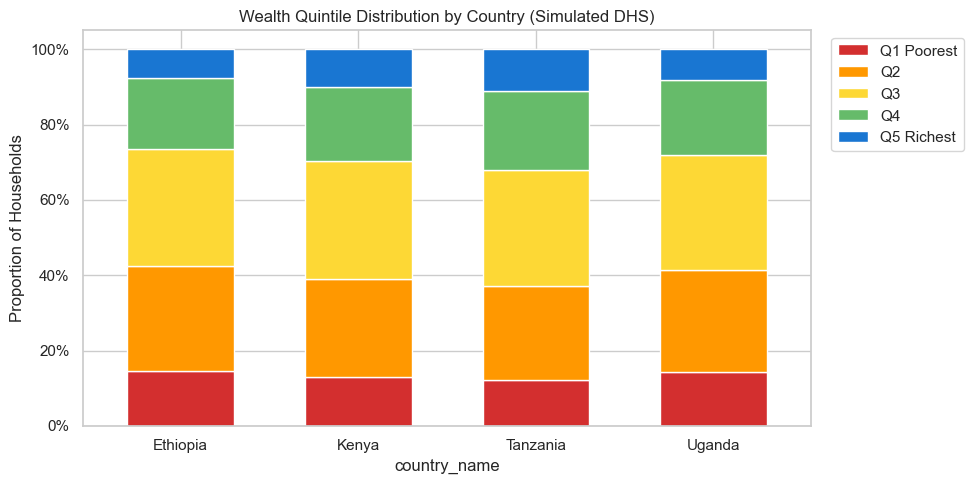

In [24]:
combined_all = pd.concat(all_dfs.values(), ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 5))

wealth_dist = (
    combined_all.groupby(["country_name", "hv270_wealth_q"])
    .size()
    .reset_index(name="count")
)
wealth_pct = wealth_dist.copy()
totals = wealth_pct.groupby("country_name")["count"].transform("sum")
wealth_pct["pct"] = wealth_pct["count"] / totals

quintile_labels = {1: "Q1 Poorest", 2: "Q2", 3: "Q3", 4: "Q4", 5: "Q5 Richest"}
wealth_pct["quintile_label"] = wealth_pct["hv270_wealth_q"].map(quintile_labels)

pivot = wealth_pct.pivot(index="country_name", columns="quintile_label", values="pct").fillna(0)
colors_wq = ["#D32F2F", "#FF9800", "#FDD835", "#66BB6A", "#1976D2"]
pivot[["Q1 Poorest", "Q2", "Q3", "Q4", "Q5 Richest"]].plot(
    kind="bar", stacked=True, ax=ax, color=colors_wq, width=0.6
)

ax.set_ylabel("Proportion of Households")
ax.set_title("Wealth Quintile Distribution by Country (Simulated DHS)", fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.legend(loc="upper right", bbox_to_anchor=(1.22, 1))
plt.tight_layout()
plt.savefig(FIGS / "01b_wealth_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## Clean Cooking Deficit vs PayGo Eligibility — Country Summary

In [25]:
summary = []
for iso, params in COUNTRY_PARAMS.items():
    df = all_dfs[iso]
    summary.append({
        "Country":             params["name"],
        "Total HHs Simulated": len(df),
        "Clean Fuel Access":   f"{df['uses_clean_fuel'].mean():.1%}",
        "Clean Cooking Deficit": f"{1 - df['uses_clean_fuel'].mean():.1%}",
        "PayGo Eligible HHs":  f"{df['paygo_eligible'].sum():,}",
        "PayGo Eligible %":    f"{df['paygo_eligible'].mean():.1%}",
        "Mobile Phone %":      f"{df['hv243a_mobile'].mean():.1%}",
        "Bank Account %":      f"{df['hv247_bank_acct'].mean():.1%}",
    })

summary_df = pd.DataFrame(summary)
tables_dir = ROOT / "outputs" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(tables_dir / "dhs_sim_country_summary.csv", index=False)
print("Saved dhs_sim_country_summary.csv")
print({tables_dir})

Saved dhs_sim_country_summary.csv
{WindowsPath('C:/Users/eric.njiraini/Documents/My Projects at a Go/paygo-cookstove-market-entry/outputs/tables')}


---

## Swap-in Instructions (when real DHS data arrives)

1. Download the household recode file for each country from dhsprogram.com (flat file format: `.DTA` Stata or `.SAV` SPSS)
2. Convert to CSV using `pyreadstat`:
   ```python
   import pyreadstat
   df, meta = pyreadstat.read_dta("KEHR8AFL.DTA")
   df.to_csv("data/raw/dhs/KE/KEHR8AFL.csv", index=False)
   ```
3. Rename the file to match the simulated path: `data/simulated/dhs_ke_households.csv`
4. The column names in this simulation already match DHS variable names (`hv025`, `hv270`, etc.), so Notebooks 02 and 03 will work without changes.

**DHS files to request:**
| Country | Survey | Household Recode File |
|---|---|---|
| Kenya | DHS 2022 | KEHR8AFL |
| Uganda | DHS 2016–17 | UGHR7BFL |
| Tanzania | DHS 2022 | TZHR8AFL |
| Ethiopia | DHS 2019 | ETHR7AFL |